In [14]:
import torch
import matplotlib.pyplot as plt

torch.manual_seed(45)


In [15]:
def generate_regression_data(n_objects, n_columns):
    #Ваги, які будемо навчати
    w = torch.zeros(n_columns)

    #Справжні ваги
    w_true = torch.normal(0,1, size=(n_columns, ))

    #Дані які буде приймати наша модель і робити передбачення
    X = torch.empty(size=(n_objects, n_columns)).uniform_(-7, 7)

    Y = torch.matmul(X, w_true) + torch.normal(0, 0.5, size=(n_objects, ))

    return X, Y, w_true, w

def mse_error(y_true, y_pred):
    #Середньоквадратична помилка для вирахування
    return torch.mean((y_true - y_pred)**2)

def l2_norm(new_w, w):
    #Функція для знаходження дистанції між минулими і теперешніми вагами
    diff = new_w - w
    squarred_diff = diff ** 2
    sum_of_squares = torch.sum(squarred_diff)
    l2_norm = torch.sqrt(sum_of_squares)

    return l2_norm

def gradient_descent(X, Y, w_true, w, eta, max_iter, min_weight_dist, display_every=None):
    #Навчання моделі шляхом градієнтного спуску

    #Ініціалізуємо дистанцію між вагами
    weight_dist = torch.inf
    iter = 0

    errors = []

    w_storage = w.clone().detach().unsqueeze(0)


    while weight_dist > min_weight_dist and iter < max_iter:

        y_pred = torch.matmul(X, w)

        dQ = 2 / Y.shape[0] * torch.matmul(X.T, y_pred - Y)

        new_w = w - (dQ * eta)

        weight_dist = l2_norm(new_w, w)

        error = mse_error(Y, y_pred)

        w = new_w
        iter += 1

        errors.append(error.item())
        w_storage = torch.concat([w_storage, new_w.unsqueeze(0)], dim=0)

        if display_every is not None and iter % display_every == 0:
            print(f"iter: {iter} | weights: {new_w} | error: {error}")

    return w, w_storage, errors

def plot_charts(w_true, w_storage, errors):
    fig, ax = plt.subplots(1, 2, figsize=(10,3))

    ax[0].scatter(w_storage[:, 0], w_storage[:, 1])
    ax[0].plot(w_storage[:, 0], w_storage[:, 1])
    ax[0].scatter(w_true[0], w_true[1])
    ax[0].set_title("Gradient Descent")

    ax[1].plot(errors)
    ax[1].set_title("Error")

    plt.tight_layout()
    plt.show()

iter: 10 | weights: tensor([-0.3106,  0.0140, -0.1883]) | error: 15.580127716064453
iter: 20 | weights: tensor([-0.5352,  0.0226, -0.3243]) | error: 8.268596649169922
iter: 30 | weights: tensor([-0.6977,  0.0278, -0.4226]) | error: 4.447135925292969
iter: 40 | weights: tensor([-0.8152,  0.0307, -0.4936]) | error: 2.4495370388031006
iter: 50 | weights: tensor([-0.9002,  0.0322, -0.5448]) | error: 1.4051933288574219
iter: 60 | weights: tensor([-0.9617,  0.0330, -0.5819]) | error: 0.8591399788856506
iter: 70 | weights: tensor([-1.0062,  0.0332, -0.6086]) | error: 0.573590874671936
iter: 80 | weights: tensor([-1.0384,  0.0332, -0.6280]) | error: 0.4242487847805023
iter: 90 | weights: tensor([-1.0617,  0.0330, -0.6419]) | error: 0.3461335003376007
iter: 100 | weights: tensor([-1.0786,  0.0328, -0.6520]) | error: 0.30526915192604065


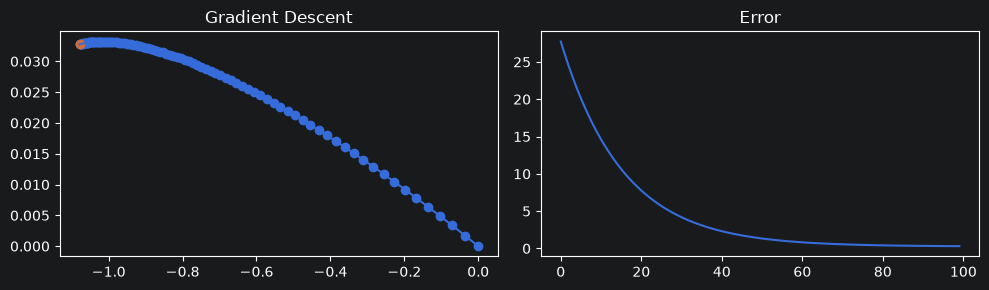

In [16]:
X, Y, w_true, w = generate_regression_data(n_objects=3000, n_columns=3)

w, w_storage, errors = gradient_descent(
    X, Y, w_true, w, eta=1e-3, max_iter=100, min_weight_dist=1e-8, display_every=10)

plot_charts(w, w_storage, errors)

In [17]:
def stochastic_gradient_descent(
    X, Y, w_true, w, eta, max_iter, min_weight_dist, display_every=None
):
    # Стохастичний градієнтний спуск (SGD)

    weight_dist = torch.inf
    iteration = 0

    # Зберігаємо історію помилок
    errors = []

    # Зберігаємо історію зміни ваг
    w_storage = w.clone().detach().unsqueeze(0)

    while weight_dist > min_weight_dist and iteration < max_iter:

        # Випадково вибираємо один об'єкт із датасету
        random_index = torch.randint(0, X.shape[0], size=(1, )).item()

        # Беремо тільки один об'єкт і його правильну відповідь
        x_random = X[random_index]
        y_random = Y[random_index]

        # Робимо передбачення тільки для цього об'єкта
        y_pred_random = x_random * w

        # Обчислюємо градієнт за одним випадковим об'єктом
        dQ = 2 * x_random * (y_pred_random - y_random)

        # Оновлюємо ваги за допомогою градієнта
        new_w = w - (eta * dQ)

        # Обчислюємо відстань між старими і новими вагами
        weight_dist = l2_norm(new_w, w)

        # Обчислюємо загальну помилку моделі
        error = mse_error(Y, torch.matmul(X, w))

        # Оновлюємо ваги
        w = new_w

        # Зберігаємо помилку
        errors.append(error.item())

        # Зберігаємо нові ваги
        w_storage = torch.cat(
            [w_storage, new_w.unsqueeze(0)], dim=0
        )

        iteration += 1

        # Виводимо результат кожні display_every ітерацій
        if display_every is not None and iteration % display_every == 0:
            print(
                f"iter: {iteration} | "
                f"weights: {new_w} | "
                f"error: {error.item()}"
            )

    return w, w_storage, errors

iter: 10 | weights: tensor([ 0.1611,  0.3117, -0.3063]) | error: 24.449012756347656
iter: 20 | weights: tensor([ 0.2027,  0.5262, -0.3247]) | error: 18.180416107177734
iter: 30 | weights: tensor([ 0.4118,  0.6171, -0.3004]) | error: 13.884356498718262
iter: 40 | weights: tensor([ 0.5930,  0.8583, -0.6990]) | error: 3.7830300331115723
iter: 50 | weights: tensor([ 0.6348,  0.8580, -0.7912]) | error: 2.361125946044922
iter: 60 | weights: tensor([ 0.6593,  0.8926, -0.8949]) | error: 3.907608985900879
iter: 70 | weights: tensor([ 0.4430,  0.8722, -0.8822]) | error: 2.0348072052001953
iter: 80 | weights: tensor([ 0.4667,  0.8149, -0.8600]) | error: 1.9392991065979004
iter: 90 | weights: tensor([ 0.6429,  1.0219, -1.0407]) | error: 1.3033537864685059
iter: 100 | weights: tensor([ 0.6147,  1.0396, -1.0258]) | error: 0.7266313433647156


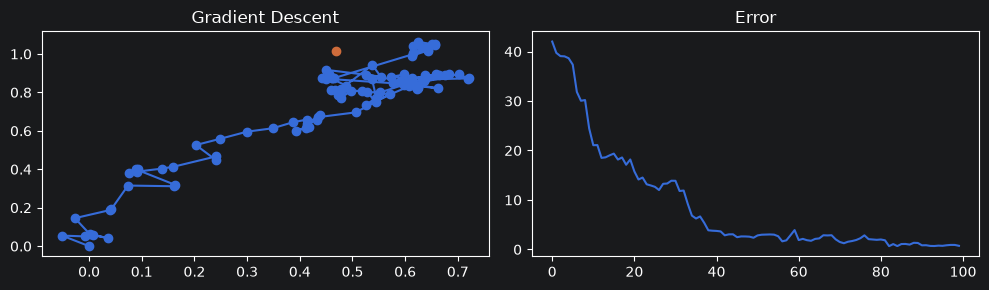

In [18]:
# Генеруємо дані
X, Y, w_true, w = generate_regression_data(
    n_objects=3000,
    n_columns=3
)

# Запускаємо стохастичний градієнтний спуск
w, w_storage, errors = stochastic_gradient_descent(
    X, Y, w_true, w,
    eta=1e-3,
    max_iter=100,
    min_weight_dist=1e-8,
    display_every=10
)

# Будуємо графіки
plot_charts(w_true, w_storage, errors)

In [19]:
def sigmoid(x):
    #Функція сігмоіди яка повертає ймовірності від 0.0 до 1.0
    return 1 / (1 + torch.exp(-x))

def BCELoss(X, Y, y_pred):
    #Binary Cross Entropy Loss.

    #Отримаємо ймовірності з логітів
    A = sigmoid(y_pred)

    #Формула втрати
    loss = -1.0 / X.shape[0] * torch.sum(Y * torch.log(A) + (1 - Y) * torch.log(1 - A))

    #Градієнт
    dQ = 1.0 / X.shape[0] * torch.matmul(X.T, A - Y)

    return loss, dQ

def calculate_accuracy(Y, y_pred):
    #Рахуємо точність прогнозів

    return torch.sum((sigmoid(y_pred) > 0.5) == Y) / Y.size(0)

def generate_classification_data(n_features, n_columns):
    w = torch.zeros(n_columns)
    w_true = torch.normal(0, 1, size=(n_columns, ))
    X = torch.randn(n_features, n_columns)
    X_w = torch.matmul(X, w_true)
    Y = (sigmoid(X_w) > 0.5).long()
    return X, Y, w_true, w

def gradient_descent_classification(X, Y, w_true, w, eta,
                     max_iter, min_weight_dist,
                     display_every=None):
  weight_dist = torch.inf
  iter = 0
  w_storage = w.clone().detach().unsqueeze(0)
  losses = []
  accuracy_list = []

  while weight_dist > min_weight_dist and iter < max_iter:
    y_pred = torch.matmul(X, w)
    loss, dQ = BCELoss(X, Y, y_pred)
    new_w = w - (dQ * eta)

    weight_dist = l2_norm(new_w, w)
    accuracy = calculate_accuracy(Y, y_pred)

    w = new_w
    iter += 1

    w_storage = torch.concat([w_storage, new_w.unsqueeze(0)], dim=0)
    losses.append(loss.item())
    accuracy_list.append(accuracy.item())

    if display_every is not None:
      if iter % display_every == 0:
        print(f"iter : {iter} | weights: {new_w} | loss: {loss.item()} | accuracy: {accuracy.item()}")

  return w, w_storage, losses, accuracy_list

In [23]:
X, Y, w_true, w = generate_classification_data(n_features=1000, n_columns=2)

w, w_storage, losses, accuracy_list = gradient_descent_classification(
    X, Y, w_true, w, eta=1e-3, max_iter=20000,
    min_weight_dist=1e-8, display_every=1000)

iter : 1000 | weights: tensor([-0.2881, -0.2191]) | loss: 0.5615186095237732 | accuracy: 0.9929999709129333
iter : 2000 | weights: tensor([-0.5166, -0.3904]) | loss: 0.47965729236602783 | accuracy: 0.9940000176429749
iter : 3000 | weights: tensor([-0.7045, -0.5295]) | loss: 0.42481234669685364 | accuracy: 0.9980000257492065
iter : 4000 | weights: tensor([-0.8642, -0.6467]) | loss: 0.3855013847351074 | accuracy: 0.9980000257492065
iter : 5000 | weights: tensor([-1.0035, -0.7479]) | loss: 0.3558100461959839 | accuracy: 0.9980000257492065
iter : 6000 | weights: tensor([-1.1272, -0.8373]) | loss: 0.3324694335460663 | accuracy: 1.0
iter : 7000 | weights: tensor([-1.2389, -0.9175]) | loss: 0.3135446012020111 | accuracy: 1.0
iter : 8000 | weights: tensor([-1.3410, -0.9903]) | loss: 0.29782119393348694 | accuracy: 1.0
iter : 9000 | weights: tensor([-1.4350, -1.0572]) | loss: 0.2844986617565155 | accuracy: 1.0
iter : 10000 | weights: tensor([-1.5224, -1.1190]) | loss: 0.2730276882648468 | accur